# Week 3 Experiment 3: Bootstrapping for Uncertainty

**Question: How much do linear regression coefficients change when we repeatedly resample the same dataset?**

This experiment uses one synthetic dataset, generates 100 bootstrap samples, fits the same type of linear regression to each sample, and compares the coefficients.

## 1. Import the tools

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression

## 2. Generate one dataset

Use 200 observations and 5 features. Three features affect the target, y. Add Gaussian noise with a standard deviation of 20.

`n` is the number of observations, `p` is the number of features, and `b` is the number of bootstrap samples. The two random seeds make the results reproducible. `coef=True` returns the true coefficients used to generate the data, so we can compare them with our estimates. Generate the original dataset only once.

In [26]:
n = 200  # Number of observations
p = 5  # Number of features
b = 100  # Number of bootstrap samples

# Fix the seeds so the results can be reproduced.
data_seed = 42
bootstrap_seed = 2026

# Generate the original dataset only once.
x, y, true_coef = make_regression(
    n_samples=n,
    n_features=p,
    n_informative=3,
    noise=20,
    coef=True,
    random_state=data_seed
)

print("Feature data shape:", x.shape)
print("Target data shape:", y.shape)
print("True coefficients:", true_coef)

Feature data shape: (200, 5)
Target data shape: (200,)
True coefficients: [ 0.         10.45678403 63.64302495 16.74825823  0.        ]


## 3. Fit the original data

`fit(x, y)` fits the model, and `coef_` contains the estimated coefficients. Keep these estimates for comparison with the bootstrap results.

In [32]:
model = LinearRegression()
model.fit(x, y)
original_coef = model.coef_
print("Coefficients from the original data:", original_coef)

Coefficients from the original data: [ 0.33517911 10.86464335 64.62033595 18.6986386  -0.70624592]


## 4. Generate 100 bootstrap samples

Each time, draw 200 row indices from the original 200 rows. `replace=True` means **sampling with replacement**, so a row can appear more than once.

In [34]:
rng = np.random.default_rng(bootstrap_seed)
bootstrap_coef = []  # Store the coefficients from each fit.

for i in range(b):
    # Sample n row indices with replacement.
    index = rng.choice(n, size=n, replace=True)
    # Use the same indices to keep features and targets paired.
    x_sample = x[index]
    y_sample = y[index]
    # Fit the same type of model to each bootstrap sample.
    model = LinearRegression()
    model.fit(x_sample, y_sample)
    # Add the estimated coefficients to the list.
    bootstrap_coef.append(model.coef_)
    
print("Completed bootstrap fits:", len(bootstrap_coef))

Completed bootstrap fits: 100


## 5. Examine the coefficients and their variation
A larger standard deviation means more variation across bootstrap samples.

In [45]:
features = ["x1", "x2", "x3", "x4", "x5"]
# Each row is one bootstrap fit; each column is one feature.
coef_table = pd.DataFrame(bootstrap_coef, columns=features)

print(coef_table.to_string())

          x1         x2         x3         x4        x5
0   0.530739  11.559757  65.968367  18.292594 -2.433849
1  -0.115462  11.936935  65.914384  18.121504  1.035341
2  -0.316269   9.975308  66.539591  20.743539  0.143904
3  -1.349366   6.948197  63.224156  17.644971 -0.608017
4  -0.999062  13.552638  64.218251  18.462377 -0.859797
5   1.316269   9.825551  64.517927  18.875319 -0.428133
6   1.634343  12.249533  60.402161  17.403990 -2.415520
7   1.257783  10.835023  64.410872  18.880710  2.175874
8   1.357225  11.369318  65.560619  18.536124 -0.759195
9   1.133894  11.754738  64.247028  19.883982  0.844088
10 -0.141707  10.016912  66.501476  16.231256  2.428994
11 -0.893451  12.219665  63.029962  22.251546 -0.293528
12  0.099177  11.635837  62.667596  22.457481  0.886072
13 -2.701829  13.189072  66.362273  17.191533  0.781329
14  0.800914  11.192490  62.431912  19.886028 -0.536026
15 -1.605477  11.431192  63.943344  19.002066 -0.472993
16 -2.534917  11.213307  66.170426  19.936644 -0

In [47]:
# Compare the original fit with the bootstrap results.
summary = pd.DataFrame(index=features)
summary["True coefficient"] = true_coef
summary["Original estimate"] = original_coef
summary["Bootstrap mean"] = coef_table.mean()
# The sample standard deviation estimates coefficient uncertainty.
summary["Bootstrap SD"] = coef_table.std()

summary.round(3)

,True coefficient,Original estimate,Bootstrap mean,Bootstrap SD
x1,0.000,0.335,0.242,1.204
x2,10.457,10.865,10.826,1.457
x3,63.643,64.620,64.724,1.440
x4,16.748,18.699,18.921,1.509
x5,0.000,-0.706,-0.423,1.694


## 6. Visualize the variation

Each box shows the distribution of one coefficient across 100 bootstrap samples.

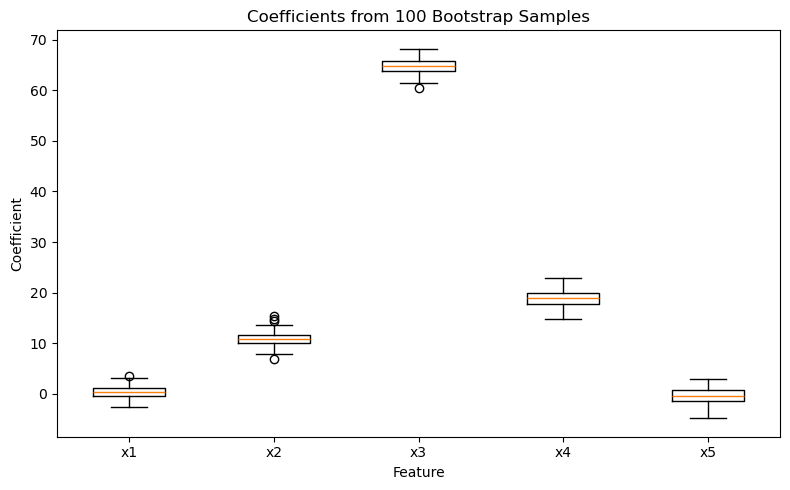

In [52]:
# Plot the coefficient distributions from all 100 fits.
plt.figure(figsize=(8, 5))
plt.boxplot(coef_table.values)
plt.xticks([1, 2, 3, 4, 5], features)
# Add a reference line at zero.
plt.xlabel("Feature")
plt.ylabel("Coefficient")
plt.title("Coefficients from 100 Bootstrap Samples")
plt.tight_layout()
plt.show()

## 7. Answer the questions

**1. How stable are the estimates across bootstrap samples?**

The standard deviations of the five coefficients range from about 1.20 to 1.69. For x3, the mean is about 64.724 and the standard deviation is about 1.440, so the variation is small relative to the coefficient's size. The standard deviation is largest for x5, at about 1.694. This shows that even when we use the same model, different samples can lead to different estimates.

**2. Are some features consistently important?**

The plot shows that the coefficients for x2, x3, and x4 stayed positive across all 100 bootstrap samples, suggesting that their effects were fairly stable. This matches how the data were generated, since these three features actually affect y. Among them, x3 had the largest coefficient. Since the features were generated on the same scale, x3 also had the strongest effect in this experiment.
In contrast, the coefficients for x1 and x5 fluctuated around zero. These features do not actually affect y, but the model still sometimes estimated nonzero coefficients for them. Therefore, we should not judge whether a feature is useful based on just one model fit.

**3. What does this tell us about uncertainty in the model?**

The model’s coefficients change depending on which observations are sampled. For example, the true coefficient for x4 is about 16.748, but the average estimate across the 100 bootstrap samples was about 18.921. Although its coefficient stayed positive, the estimates were still too high on average. This shows that stable results are not necessarily accurate.
